# Pipeline IPF: De-novo integration vs. mapping with scArches

In [2]:
# import os
# os.chdir('../')
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

We use the scArches package here, as it includes scANVI as a dependency, and we will need scArches later anyway when mapping new data to the atlas.

In [3]:
import scanpy as sc
import anndata
import torch
import scarches as sca
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [4]:
# sc.settings.set_figure_params(dpi=200, frameon=False)
# sc.set_figure_params(dpi=200)
# sc.set_figure_params(figsize=(4, 4))
torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

In [5]:
sca.__file__

'/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/scarches/__init__.py'

In [6]:
sc.logging.print_versions()

The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.7.6
scanpy      1.8.1
sinfo       0.3.4
-----
PIL                         8.3.1
absl                        NA
anyio                       NA
attr                        21.2.0
babel                       2.9.1
backcall                    0.2.0
beta_ufunc                  NA
binom_ufunc                 NA
bottleneck                  1.3.2
brotli                      NA
certifi                     2021.10.08
cffi                        1.14.6
chardet                     4.0.0
charset_normali

## 0. Import all relevant datasets

First run notebook: LCA_prep_healthy
- Set labels (cell type harmonization)
- scran normalize counts (not log-transformed!)

query_data:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

source_adata:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

atlas_data:
- .X: subsetted raw count data for reference atlas (only the 2000 HVGs)

In [7]:
query_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/IPF_labeled_normalized.h5ad")

In [8]:
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v4.h5ad")

In [9]:
atlas_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")
atlas_data.var.index = atlas_data.var.gene_ids

## 1. Perform de-novo integration

### 1.1 Preparation

In [9]:
source_adata.var = source_adata.var.set_index("gene_ids")

In [10]:
combined_data = source_adata.concatenate(query_data, join="outer")

In [11]:
combined_data.X = np.nan_to_num(combined_data.X, copy=False)

In [12]:
combined_data.var["highly_variable-0"].fillna(False, inplace=True)

Create two datasets: 
- combined_data: recalculate hvgs and take top 2000
- combined_data_ref_hvg: take 2000 hvg calculated on reference atlas

In [13]:
combined_data_ref_hvg = combined_data[:,combined_data.var["highly_variable-0"]].copy()

In [14]:
combined_data_ref_hvg.X = combined_data_ref_hvg.layers['counts'].copy()

For further learning get back raw counts for query data

In [10]:
query_data.X = query_data.layers['counts'].copy()

Recalculate highly variable genes

In [16]:
# function to calculate variances on *sparse* matrix
def vars(a, axis=None):
    """ Variance of sparse matrix a
    var = mean(a**2) - mean(a)**2
    """
    a_squared = a.copy()
    a_squared.data **= 2
    return a_squared.mean(axis) - np.square(a.mean(axis))

calculate mean, variance, dispersion per gene:

In [17]:
means = np.mean(combined_data.X, axis=0)

In [18]:
variances = vars(combined_data.X, axis=0)

In [19]:
dispersions = variances / means

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in true_divide
  """Entry point for launching an IPython kernel.


set min_mean cutoff (base this on the plot). We do not want to include the leftmost noisy genes that have high dispersions due to low means.

In [20]:
min_mean = 0.06

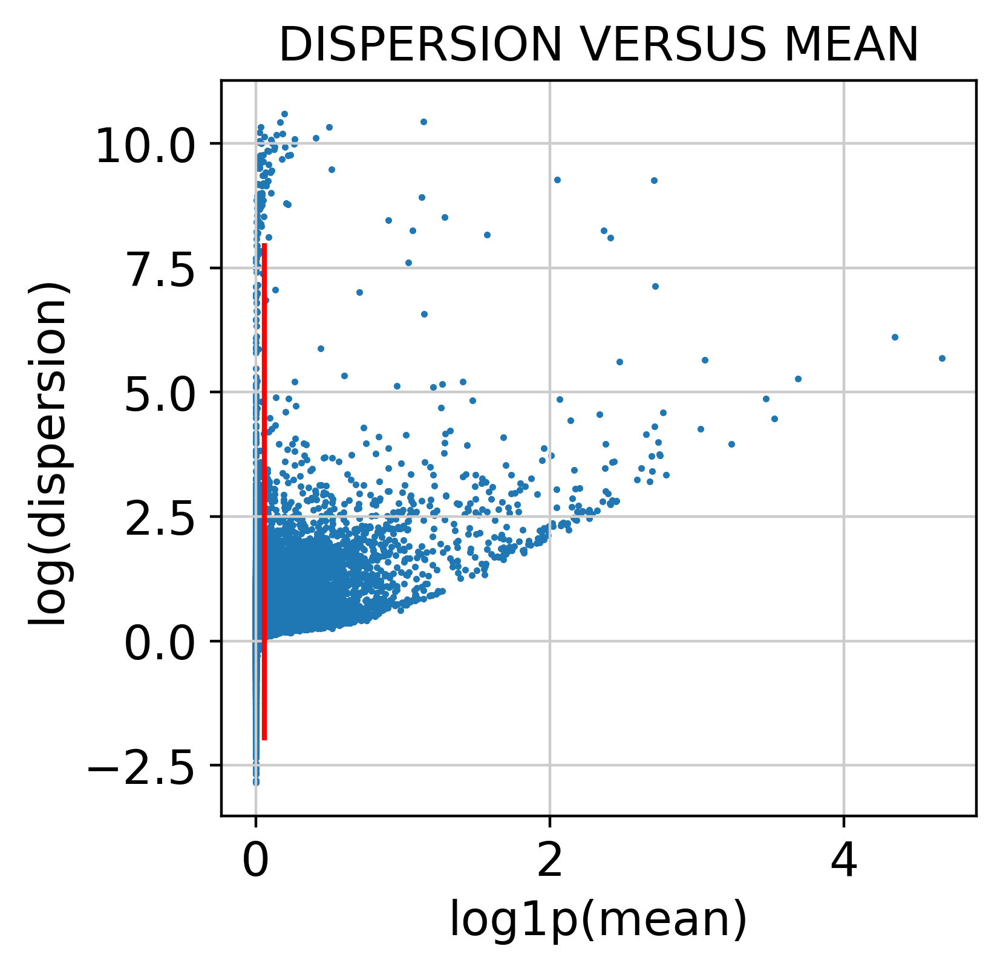

In [21]:
# plot mean versus dispersion plot:
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1,
    
)
plt.vlines(x=np.log1p(min_mean),ymin=-2,ymax=8,color='red')
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

log-transform data:

In [22]:
sc.pp.log1p(combined_data)

now calculate highly variable genes:

In [23]:
sc.pp.highly_variable_genes(combined_data, batch_key="dataset", min_mean=min_mean, flavor="cell_ranger", n_top_genes=2000)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/pandas/core/indexing.py:1732: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a 

In [24]:
combined_data.raw = combined_data

check selection of genes:

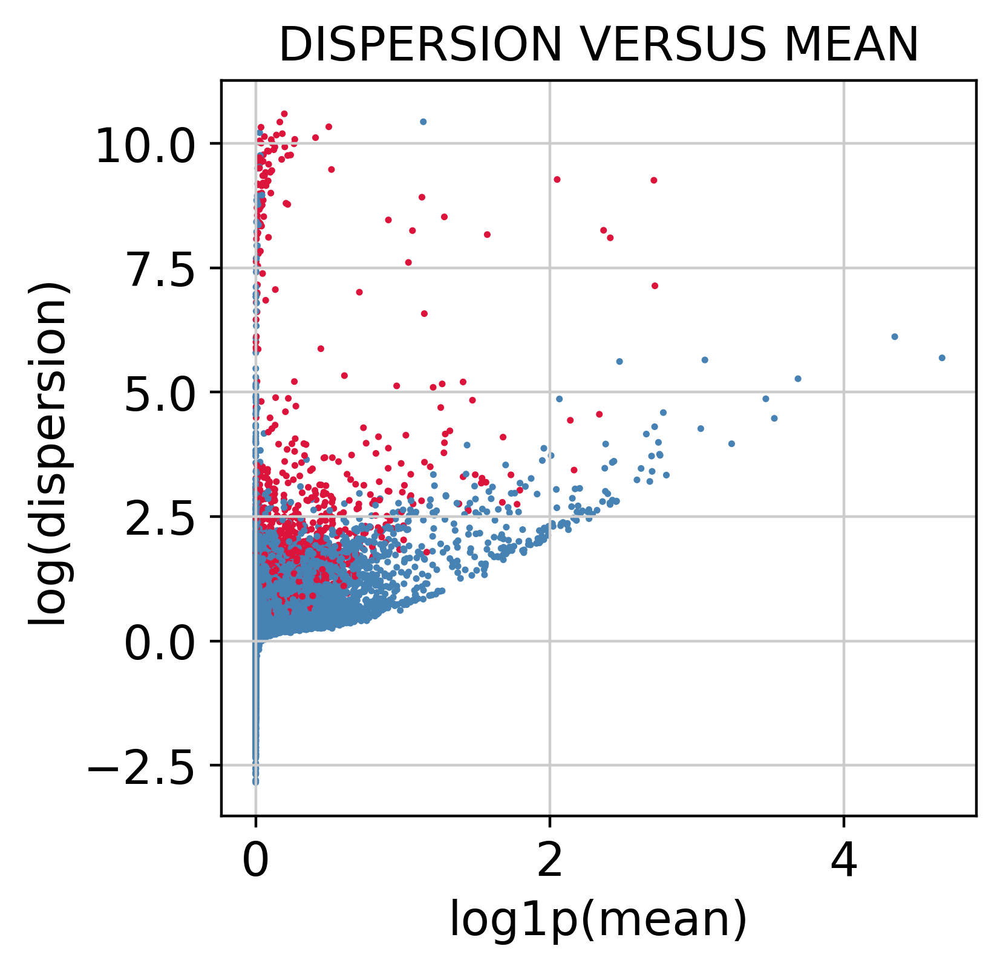

In [25]:
boolean_to_color = {
    True: "crimson",
    False: "steelblue",
}  # make a dictionary that translates the boolean to colors
hvg_colors = combined_data.var.highly_variable.map(boolean_to_color)  # 'convert' the boolean
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1, c=hvg_colors
)
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

Subset data to the calculated top 2000 highly variable genes

In [26]:
combined_data = combined_data[:,combined_data.var.highly_variable].copy()

In [27]:
np.unique(query_data.obs.study)

array(['Banovich_Kropski_2020', 'Kaminski_2020', 'Misharin_Budinger_2018',
       'Sheppard_2020'], dtype=object)

Check if additional genes from adams/kamisnki dataset were not selected as hvgs

In [28]:
genes_to_keep = pd.read_csv("/storage/groups/ml01/workspace/jan.domke/Data/Homo_sapiens_GRCh38_84_gene_ids_to_keep_cellrangerbased.txt", header=None)

In [29]:
genes_to_keep.rename(columns={0:"gene_id"},inplace=True)
genes_to_keep = genes_to_keep.gene_id.tolist()

In [30]:
kaminski = query_data[query_data.obs.study=="Kaminski_2020"]

In [31]:
not_cell_ranger = kaminski.var.index[~kaminski.var.index.isin(genes_to_keep)]

In [32]:
np.sum(combined_data.var.index.isin(not_cell_ranger))

0

Go back to raw counts

In [33]:
combined_data.X = combined_data.layers["counts"].copy()

In [34]:
np.unique(source_adata.obs.scanvi_label)

array(['AT1', 'AT2', 'Arterial EC', 'B cell lineage', 'Basal',
       'Bronchial Vessel 1', 'Bronchial Vessel 2', 'Capillary',
       'Ciliated', 'Dendritic cells', 'Fibroblast lineage',
       'KRT5- KRT17+ epithelial', 'Lymphatic EC', 'Macrophages',
       'Mast cells', 'Megakaryocytes', 'Mesothelium', 'Monocytes',
       'Neutrophilic', 'Non-T/B cells', 'Proliferating cells', 'Rare',
       'Secretory', 'Smooth muscle', 'Squamous', 'Submucosal Secretory',
       'T cell lineage', 'Venous', 'unlabeled'], dtype=object)

### 1.2 scVI and scANVI model with newly calculated HVGs

In [11]:
condition_key = 'dataset'
cell_type_key = 'scanvi_label'
unlabeled_category = "unlabeled"

scvi_epochs = 500
scanvi_epochs = 200

In [36]:
sca.dataset.setup_anndata(combined_data, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             


Using batches from adata.obs["dataset"]


INFO     Using labels from adata.obs["scanvi_label"]                                         


Using labels from adata.obs["scanvi_label"]


INFO     Using data from adata.X                                                             


...

Computing library size prior per batch


INFO     Successfully registered anndata object containing 1092343 cells, 2000 vars, 18      
         batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 1092343 cells, 2000 vars, 18 batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


INFO     Please do not further modify adata until model is trained.                          


Please do not further modify adata until model is trained.


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [37]:
scvi_model = sca.models.SCVI(
    combined_data,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

In [38]:
scvi_model.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 424/500:  85%|████████▍ | 424/500 [9:28:11<1:41:50, 80.40s/it, loss=570, v_num=1]


In [39]:
scvi_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI")

ValueError: /storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI already exists. Please provide an unexisting directory for saving.

In [36]:
scvi_model = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI", combined_data)

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 1092343 cells, 2000 vars, 18      
         batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 1092343 cells, 2000 vars, 18 batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [37]:
combined_data.obsm["X_scVI"] = scvi_model.get_latent_representation()

In [38]:
sc.pp.neighbors(combined_data, use_rep="X_scVI")
sc.tl.leiden(combined_data)
sc.tl.umap(combined_data)

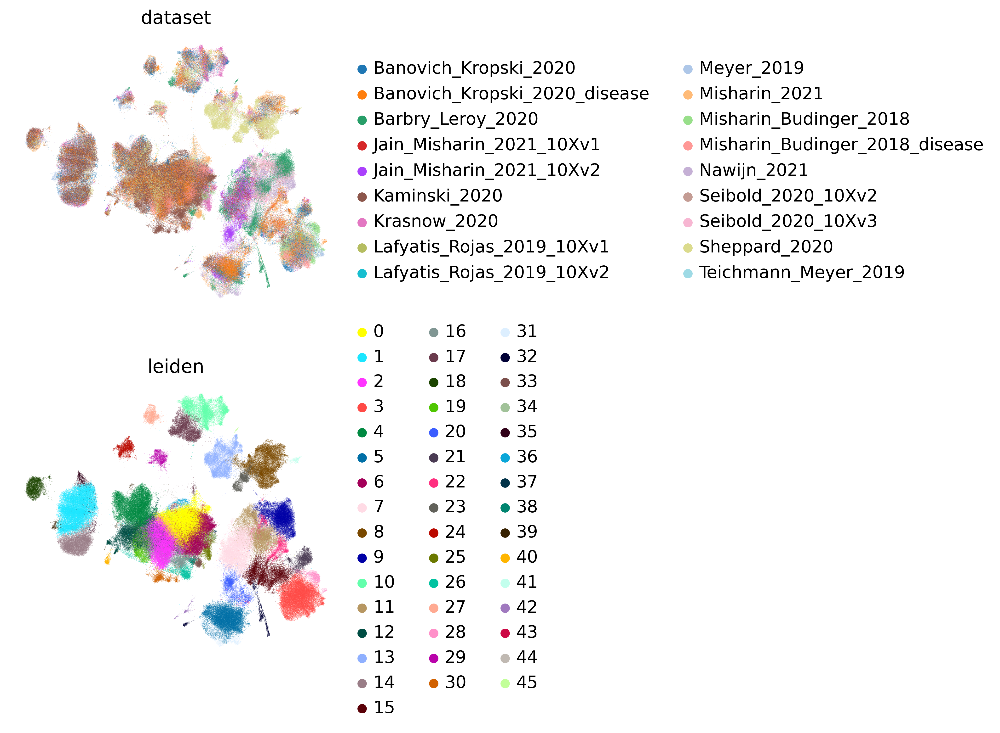

In [39]:
sc.pl.umap(
    combined_data,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

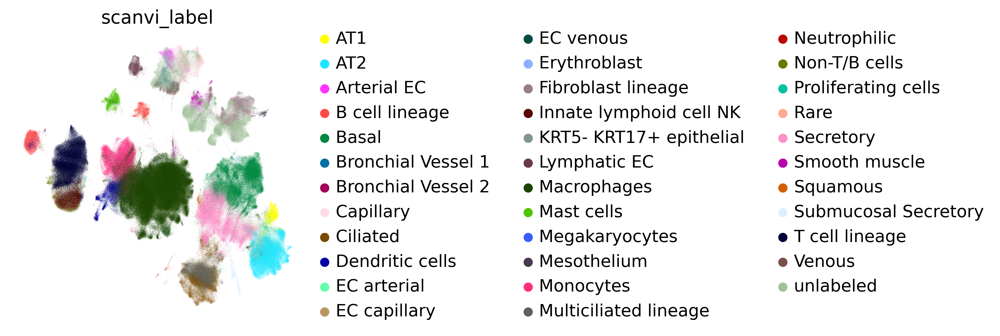

In [40]:
sc.pl.umap(combined_data, color=cell_type_key, frameon=False)

In [41]:
scANVI_model = sca.models.SCANVI.from_scvi_model(scvi_model, unlabeled_category, adata=combined_data)

In [42]:
scANVI_model.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

INFO     Training for 200 epochs.                                                            


Training for 200 epochs.
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 119/200:  60%|█████▉    | 119/200 [5:50:05<3:58:17, 176.51s/it, loss=662, v_num=1]


In [43]:
scANVI_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scANVI")

In [44]:
#scANVI_model = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI", combined_data)

In [45]:
print("Labelled Indices: ", len(scANVI_model._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model._unlabeled_indices))

Labelled Indices:  998184
Unlabelled Indices:  94159


In [46]:
combined_data.obs["C_scANVI"] = scANVI_model.predict(combined_data)
combined_data.obsm["X_scANVI"] = scANVI_model.get_latent_representation(combined_data)

In [47]:
sc.pp.neighbors(combined_data, use_rep="X_scANVI")
sc.tl.umap(combined_data)

... storing 'C_scANVI' as categorical


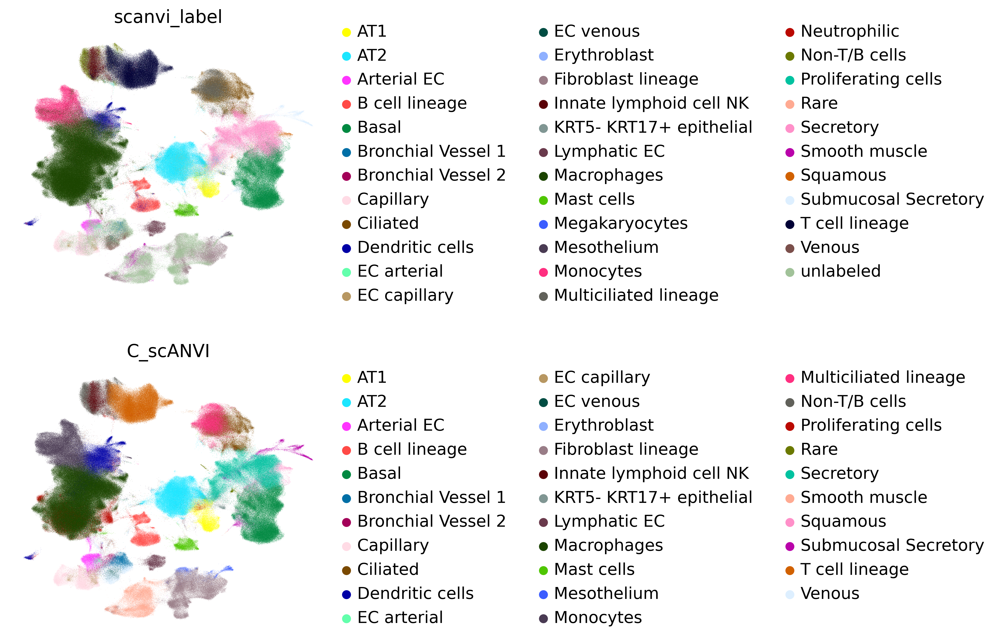

In [48]:
sc.pl.umap(combined_data, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

In [49]:
df = combined_data.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

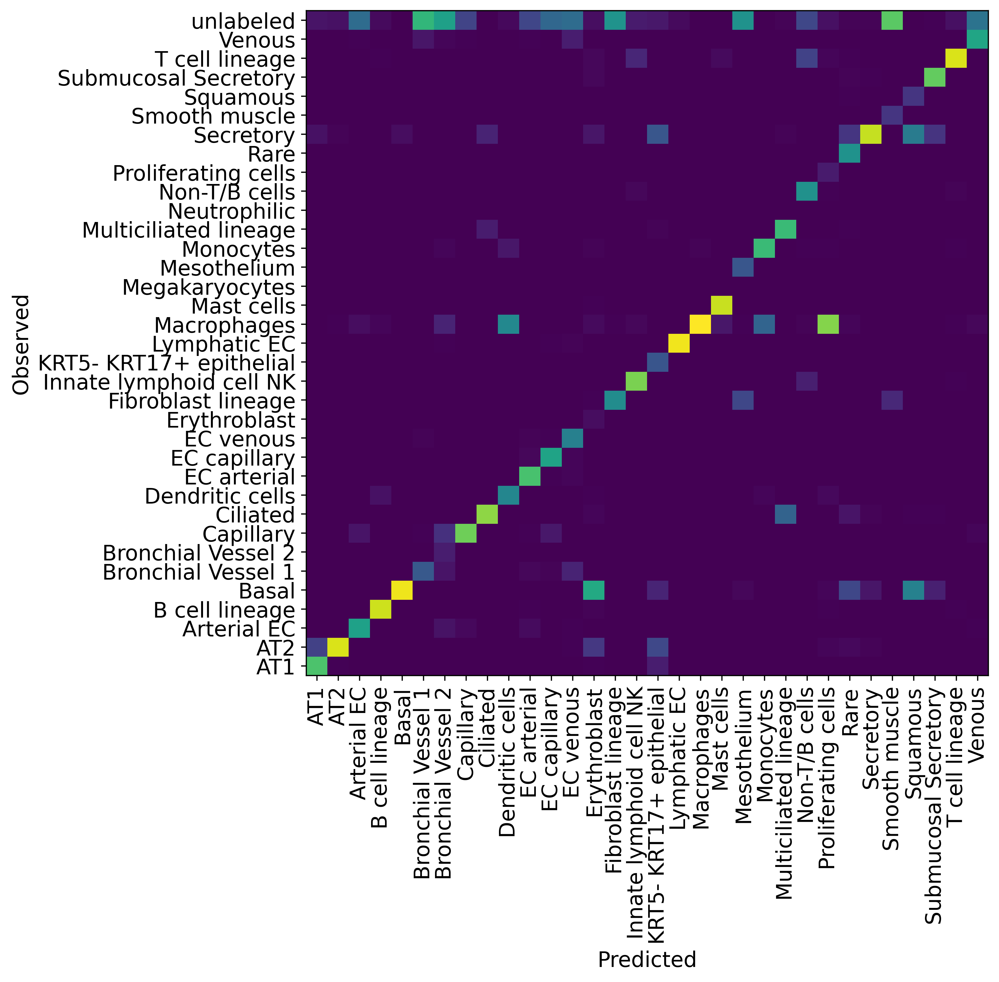

In [50]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [51]:
combined_data.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo.h5ad")

### 1.3 scVI and scANVI model with old reference HVGs

In [52]:
sca.dataset.setup_anndata(combined_data_ref_hvg, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             


Using batches from adata.obs["dataset"]


INFO     Using labels from adata.obs["scanvi_label"]                                         


Using labels from adata.obs["scanvi_label"]


INFO     Using data from adata.X                                                             


...

Computing library size prior per batch


INFO     Successfully registered anndata object containing 1092343 cells, 2000 vars, 18      
         batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 1092343 cells, 2000 vars, 18 batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


INFO     Please do not further modify adata until model is trained.                          


Please do not further modify adata until model is trained.


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [53]:
scvi_model_ref_hvg = sca.models.SCVI(
    combined_data_ref_hvg,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

In [54]:
scvi_model_ref_hvg.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 429/500:  86%|████████▌ | 429/500 [12:23:20<2:03:01, 103.96s/it, loss=621, v_num=1]


In [55]:
scvi_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI_ref_hvg")

In [56]:
scvi_model_ref_hvg = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 1092343 cells, 2000 vars, 18      
         batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 1092343 cells, 2000 vars, 18 batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [57]:
combined_data_ref_hvg.obsm["X_scVI"] = scvi_model_ref_hvg.get_latent_representation()

In [58]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scVI")
sc.tl.leiden(combined_data_ref_hvg)
sc.tl.umap(combined_data_ref_hvg)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical


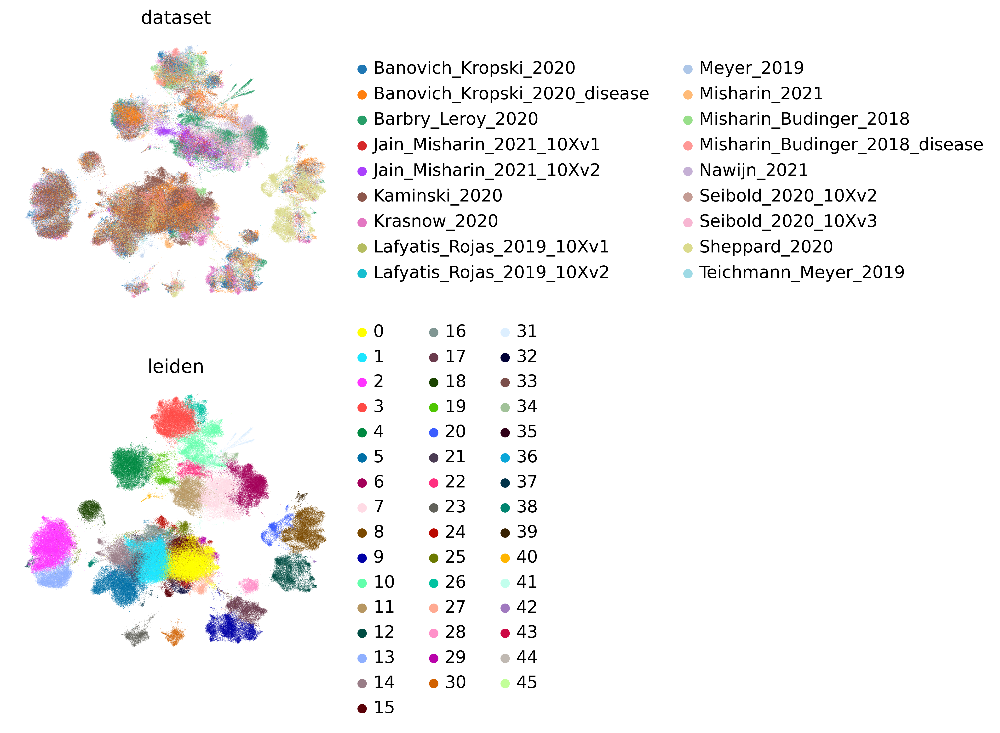

In [59]:
sc.pl.umap(
    combined_data_ref_hvg,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

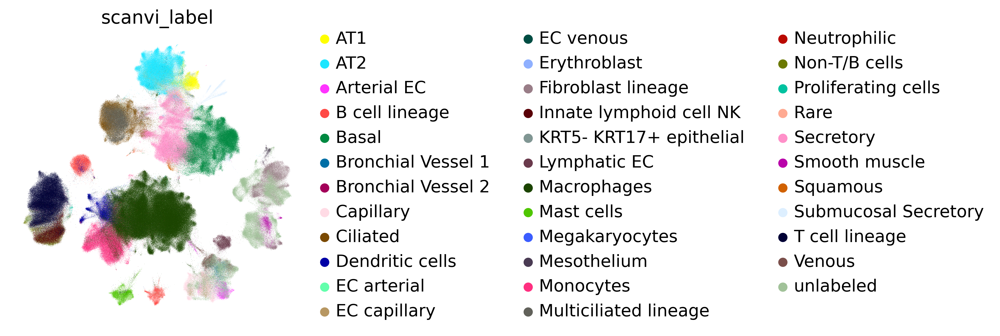

In [60]:
sc.pl.umap(combined_data_ref_hvg, color=cell_type_key, frameon=False)

In [61]:
scANVI_model_ref_hvg = sca.models.SCANVI.from_scvi_model(scvi_model_ref_hvg, unlabeled_category, adata=combined_data_ref_hvg)

In [62]:
scANVI_model_ref_hvg.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

INFO     Training for 200 epochs.                                                            


Training for 200 epochs.
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 113/200:  56%|█████▋    | 113/200 [6:05:09<4:41:08, 193.89s/it, loss=731, v_num=1]


In [63]:
scANVI_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scANVI_ref_hvg")

In [64]:
scANVI_model_ref_hvg = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scANVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 1092343 cells, 2000 vars, 18      
         batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 1092343 cells, 2000 vars, 18 batches, 35 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [65]:
print("Labelled Indices: ", len(scANVI_model_ref_hvg._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model_ref_hvg._unlabeled_indices))

Labelled Indices:  998184
Unlabelled Indices:  94159


In [66]:
combined_data_ref_hvg.obs["C_scANVI"] = scANVI_model_ref_hvg.predict(combined_data_ref_hvg)
combined_data_ref_hvg.obsm["X_scANVI"] = scANVI_model_ref_hvg.get_latent_representation(combined_data_ref_hvg)

In [67]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scANVI")
sc.tl.umap(combined_data_ref_hvg)

... storing 'C_scANVI' as categorical


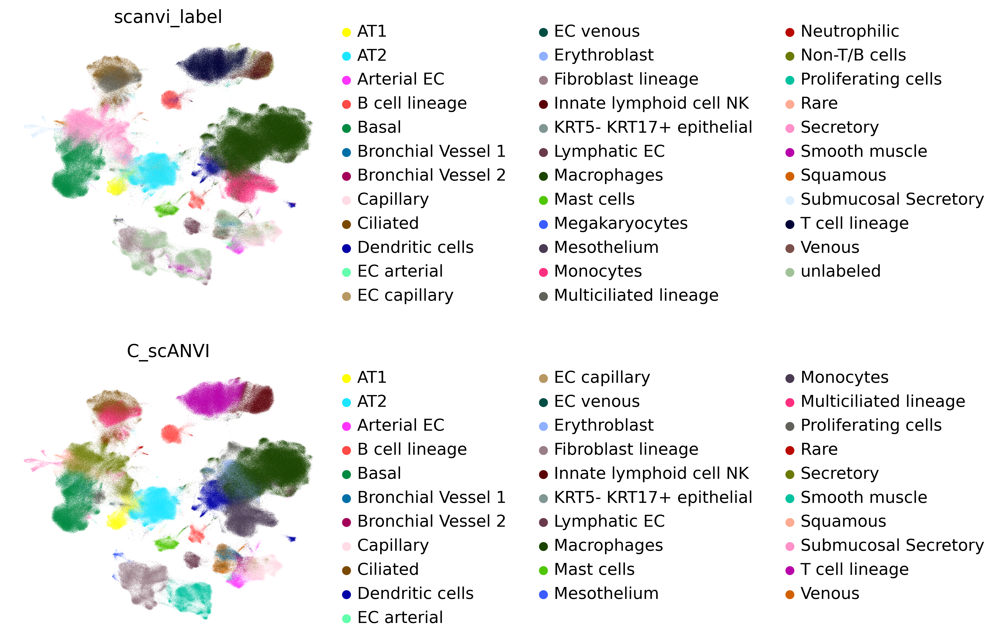

In [68]:
sc.pl.umap(combined_data_ref_hvg, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

In [69]:
df = combined_data_ref_hvg.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

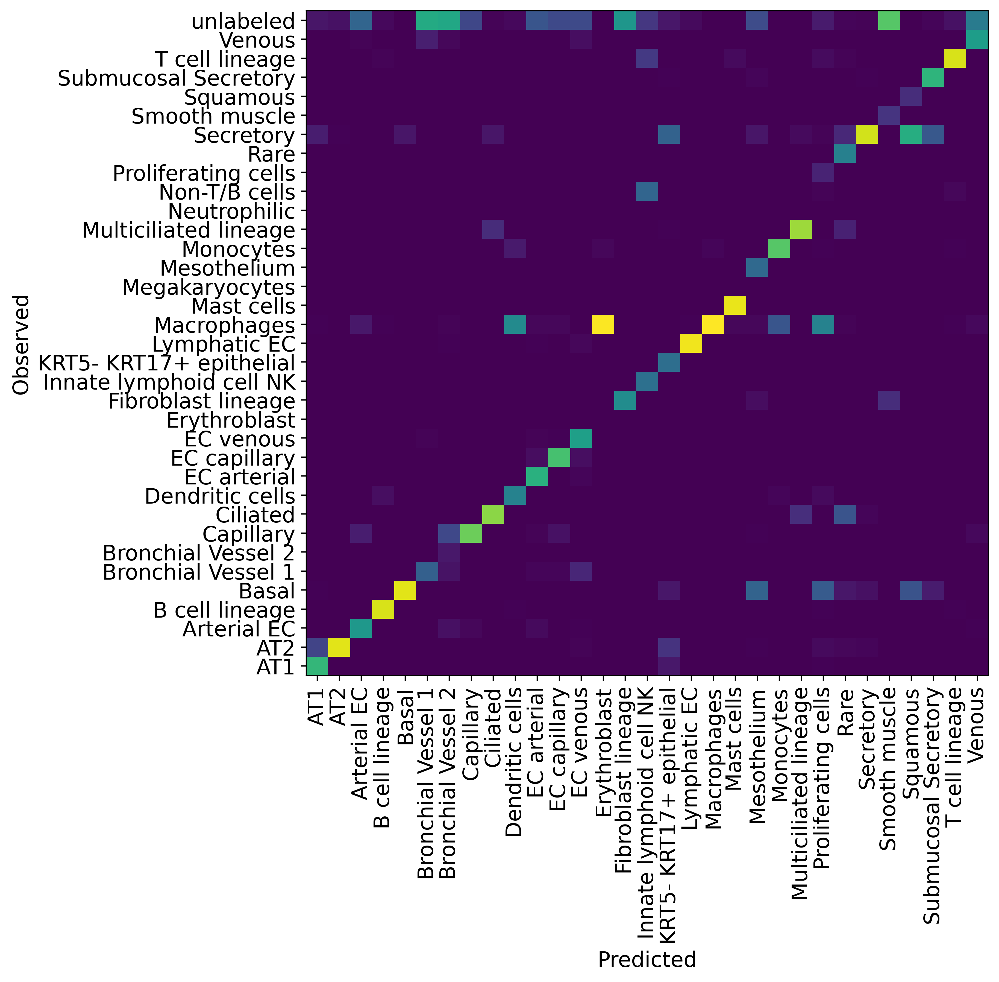

In [70]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [71]:
combined_data_ref_hvg.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/IPF_atlas_denovo_ref_hvg.h5ad")

## 2. scArches | Perform surgery 

### 2.1 Unlabeled scArches

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set all labels to unlabeled

In [12]:
scANVI_model_original = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scANVI", atlas_data)

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 584884 cells, 2000 vars, 14 batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [13]:
query_data.obs["scanvi_label_original"]=query_data.obs["scanvi_label"]

In [14]:
query_data.obs["scanvi_label"]=scANVI_model_original.unlabeled_category_

In [15]:
query_data_scArches = query_data[:,atlas_data.var.gene_ids].copy()

In [16]:
scArches_model = sca.models.SCANVI.load_query_data(
    query_data_scArches,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model._unlabeled_indices = np.arange(query_data_scArches.n_obs)
scArches_model._labeled_indices = []
print("Labelled Indices: ", len(scArches_model._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model._unlabeled_indices))

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 507459 cells, 2000 vars, 18       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 507459 cells, 2000 vars, 18 batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


Labelled Indices:  0
Unlabelled Indices:  507459


In [17]:
scArches_model.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))

INFO     Training for 200 epochs.                                                            


Training for 200 epochs.
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [2:26:58<00:00, 44.09s/it, loss=699, v_num=1]  


In [18]:
query_data_scArches_full = atlas_data.concatenate(query_data_scArches)
query_data_scArches_full.obs["C_scArches"] = scArches_model.predict(query_data_scArches_full)
query_data_scArches_full.obsm["X_scArches"] = scArches_model.get_latent_representation(query_data_scArches_full)

INFO     Input adata not setup with scvi. attempting to transfer anndata setup               


Input adata not setup with scvi. attempting to transfer anndata setup


INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 1092343 cells, 2000 vars, 18      
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 1092343 cells, 2000 vars, 18 batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [19]:
sc.pp.neighbors(query_data_scArches_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_full)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
... storing 'C_scArches' as categorical


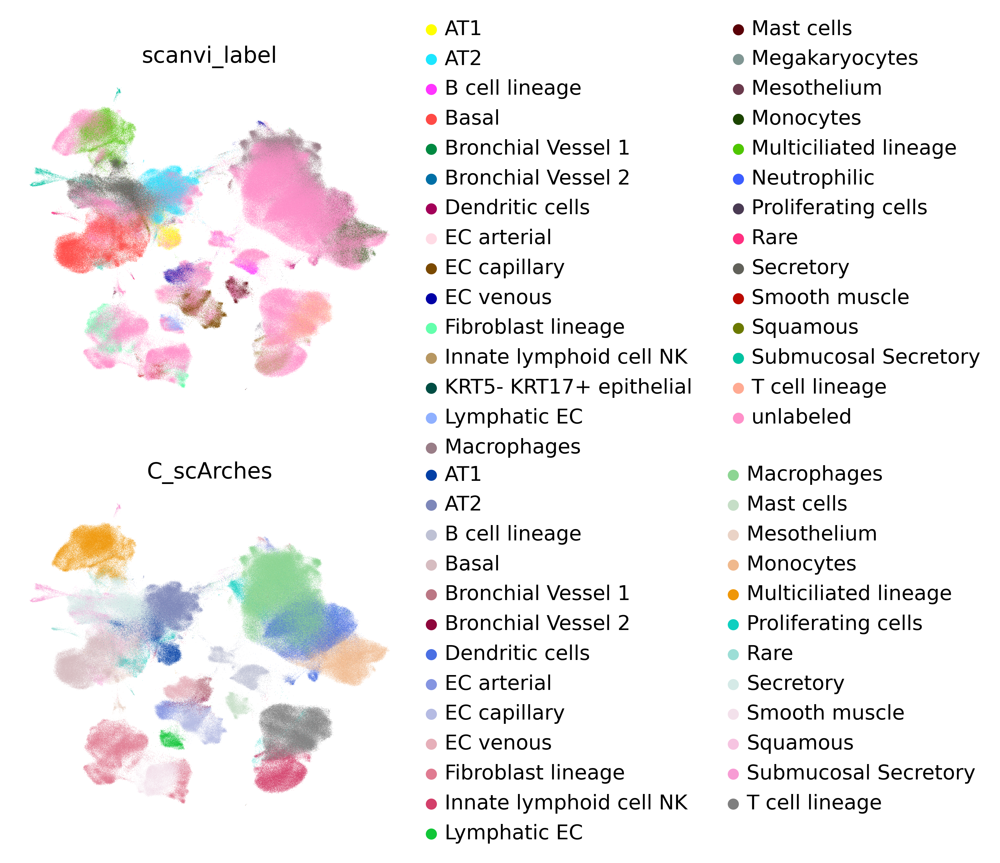

In [20]:
sc.pl.umap(query_data_scArches_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

In [21]:
df = query_data_scArches_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

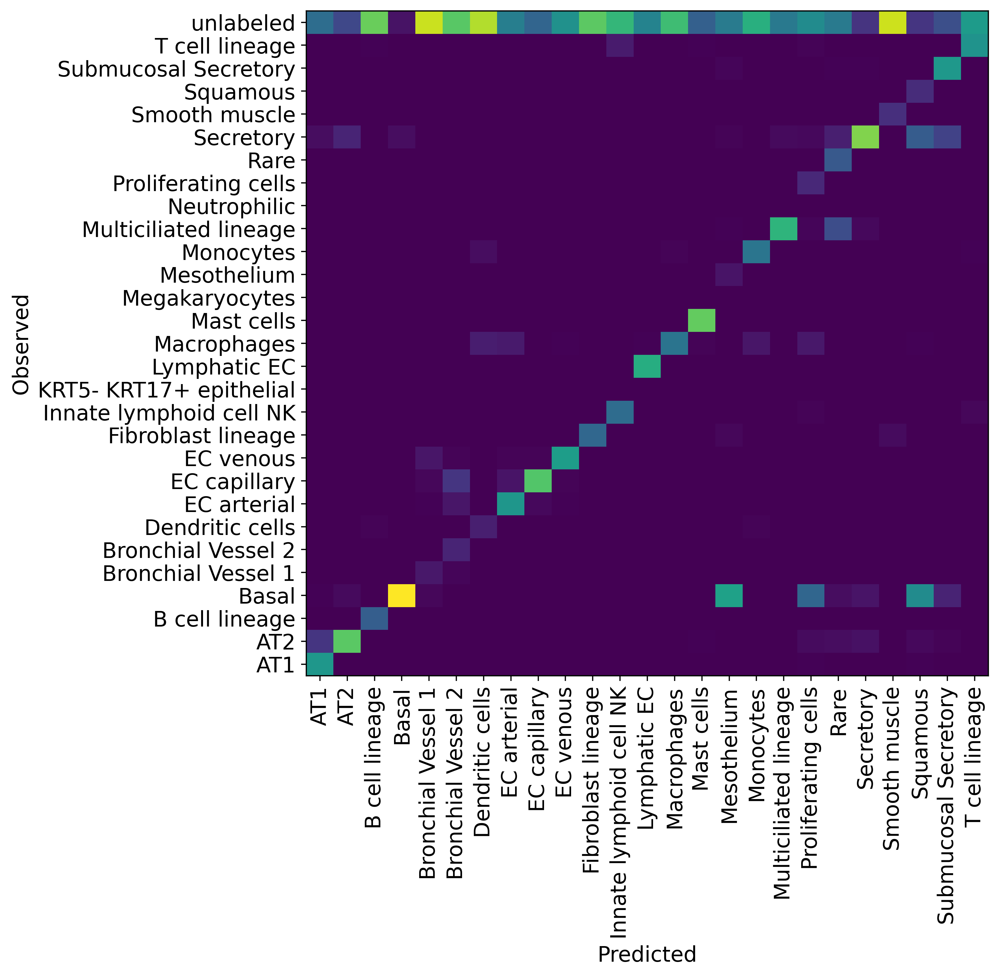

In [22]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [ ]:
query_data_scArches_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_full.h5ad")

### 2.2 Labeled scArches

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set labels to unlabeled which are not in the atlas

In [23]:
mask_unlabeled = [x for x in set(query_data.obs.scanvi_label_original) if x not in set(atlas_data.obs.scanvi_label)]

In [24]:
set(query_data.obs.scanvi_label_original)

{'AT1',
 'AT2',
 'B cell lineage',
 'Basal',
 'Bronchial Vessel 1',
 'Dendritic cells',
 'EC arterial',
 'EC capillary',
 'EC venous',
 'Erythroblast',
 'Fibroblast lineage',
 'Innate lymphoid cell NK',
 'KRT5- KRT17+ epithelial',
 'Lymphatic EC',
 'Macrophages',
 'Mast cells',
 'Mesothelium',
 'Monocytes',
 'Multiciliated lineage',
 'Rare',
 'Secretory',
 'Smooth muscle',
 'T cell lineage',
 'unlabeled'}

In [25]:
set(atlas_data.obs.scanvi_label)

{'AT1',
 'AT2',
 'B cell lineage',
 'Basal',
 'Bronchial Vessel 1',
 'Bronchial Vessel 2',
 'Dendritic cells',
 'EC arterial',
 'EC capillary',
 'EC venous',
 'Fibroblast lineage',
 'Innate lymphoid cell NK',
 'KRT5- KRT17+ epithelial',
 'Lymphatic EC',
 'Macrophages',
 'Mast cells',
 'Megakaryocytes',
 'Mesothelium',
 'Monocytes',
 'Multiciliated lineage',
 'Neutrophilic',
 'Proliferating cells',
 'Rare',
 'Secretory',
 'Smooth muscle',
 'Squamous',
 'Submucosal Secretory',
 'T cell lineage',
 'unlabeled'}

In [26]:
mask_unlabeled

['Erythroblast']

In [27]:
query_data.obs["scanvi_label"][query_data.obs["scanvi_label_original"].isin(mask_unlabeled)] = scANVI_model_original.unlabeled_category_

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [28]:
query_data.obs["scanvi_label"][~query_data.obs["scanvi_label_original"].isin(mask_unlabeled)] = query_data.obs["scanvi_label_original"][~query_data.obs["scanvi_label_original"].isin(mask_unlabeled)]

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [29]:
query_data_scArches_labeled = query_data[:,atlas_data.var.gene_ids].copy()

In [30]:
[x for x in set(query_data_scArches_labeled.obs.scanvi_label) if x not in set(atlas_data.obs.scanvi_label)]
# if empty set, then all labels in query data are in atlas data contained

[]

In [31]:
scArches_model_labeled = sca.models.SCANVI.load_query_data(
    query_data_scArches_labeled,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model_labeled._unlabeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]==scArches_model_labeled.unlabeled_category_))[0]
scArches_model_labeled._labeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]!=scArches_model_labeled.unlabeled_category_))[0]
print("Labelled Indices: ", len(scArches_model_labeled._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model_labeled._unlabeled_indices))

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 507459 cells, 2000 vars, 18       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 507459 cells, 2000 vars, 18 batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


Labelled Indices:  437448
Unlabelled Indices:  70011


In [32]:
scArches_model_labeled.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))
query_data_scArches_labeled.obsm["X_scArches"] = scArches_model_labeled.get_latent_representation()

INFO     Training for 200 epochs.                                                            


Training for 200 epochs.
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [3:03:58<00:00, 55.19s/it, loss=839, v_num=1]  


In [33]:
query_data_scArches_labeled_full = atlas_data.concatenate(query_data_scArches_labeled)
query_data_scArches_labeled_full.obs["C_scArches"] = scArches_model_labeled.predict(query_data_scArches_labeled_full)
query_data_scArches_labeled_full.obsm["X_scArches"] = scArches_model_labeled.get_latent_representation(query_data_scArches_labeled_full)

INFO     Input adata not setup with scvi. attempting to transfer anndata setup               


Input adata not setup with scvi. attempting to transfer anndata setup


INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 1092343 cells, 2000 vars, 18      
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 1092343 cells, 2000 vars, 18 batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [34]:
sc.pp.neighbors(query_data_scArches_labeled_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_labeled_full)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
... storing 'C_scArches' as categorical


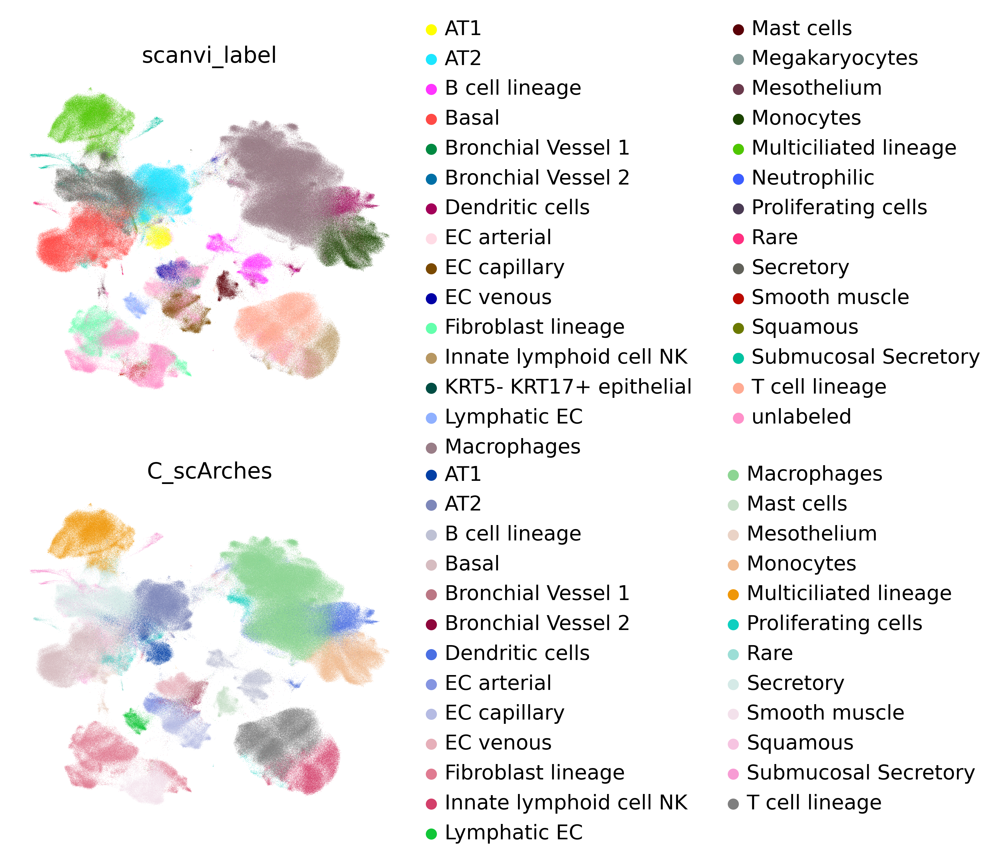

In [35]:
sc.pl.umap(query_data_scArches_labeled_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

In [36]:
df = query_data_scArches_labeled_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

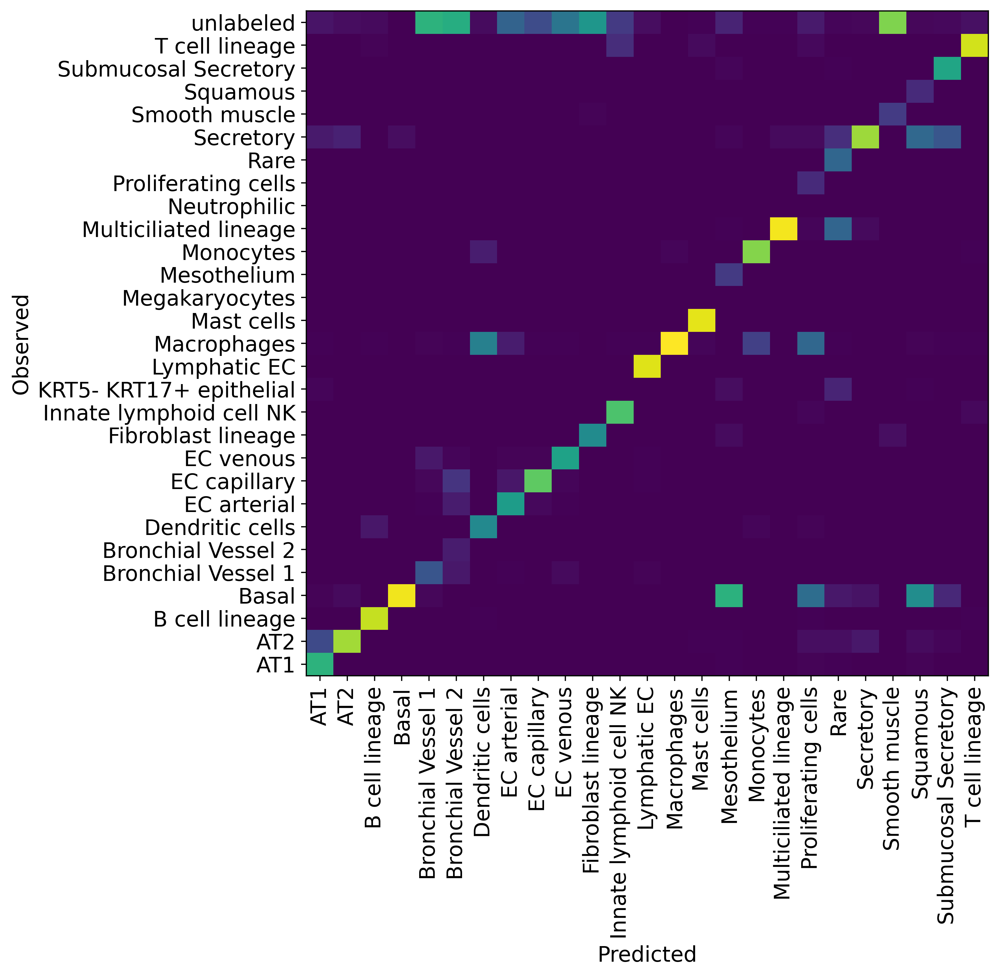

In [37]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [38]:
query_data_scArches_labeled_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_labeled_full.h5ad")